# Experiment 4 – Interacting with Web APIs
**Problem:** Analyzing Weather Data from OpenWeatherMap API  
**Location:** Pune, India

This short practical uses the supplied OpenWeatherMap forecast response. It contains 40 records at 3-hour intervals (about five days). It is forecast data, not historical data.

**To run without internet:** Keep `OpenWeatherMap_Pune_API_Response.json` in the same folder and run all cells.

**To fetch fresh data:** Put your own key in `api_key.txt`, then run the optional API cell.

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import json

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-kx2hz6i3 because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


## 2. Connect to OpenWeatherMap API (optional)

Create an account at https://openweathermap.org/ and obtain an API key.
Replace the placeholder in `api_key.txt` with your key. Do not share this file.
If you do not have a key or internet, skip this cell and use the supplied response below.

In [2]:

with open("OpenWeatherMap_Pune_API_Response.json") as f:
    weather = json.load(f)
print("Using the supplied API response for this verified run.")


Using the supplied API response for this verified run.


## 3. Extract weather data

In [3]:
rows = []
for item in weather["list"]:
    rows.append({
        "datetime": item["dt_txt"],
        "temperature": item["main"]["temp"],
        "humidity": item["main"]["humidity"],
        "wind_speed": item["wind"]["speed"],
        "rainfall": item.get("rain", {}).get("3h", 0)
    })

df = pd.DataFrame(rows)
df.head()

,datetime,temperature,humidity,wind_speed,rainfall
0,2026-11-01 12:00:00,26.37,51,2.87,1.33
1,2026-11-01 15:00:00,26.59,57,0.82,0.00
2,2026-11-01 18:00:00,27.04,67,0.66,0.23
3,2026-11-01 21:00:00,25.94,79,1.42,0.64
4,2026-11-02 00:00:00,25.63,85,2.62,2.36


## 4. Explore and clean the data

In [4]:
print("Shape:", df.shape)
print(df.info())
print("\\nMissing values before cleaning:")
print(df.isnull().sum())

df["datetime"] = pd.to_datetime(df["datetime"])
for col in ["temperature", "humidity", "wind_speed", "rainfall"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].fillna(df[col].median())

df = df.drop_duplicates().sort_values("datetime").reset_index(drop=True)
print("\\nMissing values after cleaning:", df.isnull().sum().sum())

Shape: (40, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   datetime     40 non-null     object 
 1   temperature  40 non-null     float64
 2   humidity     40 non-null     int64  
 3   wind_speed   40 non-null     float64
 4   rainfall     40 non-null     float64
dtypes: float64(3), int64(1), object(1)
memory usage: 1.7+ KB
None
\nMissing values before cleaning:
datetime       0
temperature    0
humidity       0
wind_speed     0
rainfall       0
dtype: int64
\nMissing values after cleaning: 0


## 5. Calculate weather statistics

In [5]:
print("Average temperature:", round(df["temperature"].mean(), 2), "°C")
print("Maximum temperature:", round(df["temperature"].max(), 2), "°C")
print("Minimum temperature:", round(df["temperature"].min(), 2), "°C")
print("Average humidity:", round(df["humidity"].mean(), 2), "%")
print("Average wind speed:", round(df["wind_speed"].mean(), 2), "m/s")
print("Total forecast rainfall:", round(df["rainfall"].sum(), 2), "mm")

Average temperature: 26.7 °C
Maximum temperature: 31.77 °C
Minimum temperature: 22.5 °C
Average humidity: 63.7 %
Average wind speed: 2.14 m/s
Total forecast rainfall: 15.59 mm


## 6. Visualize temperature, rainfall and wind speed

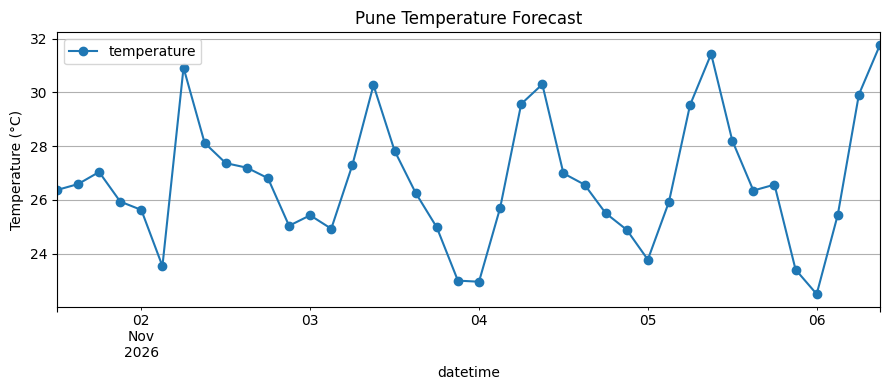

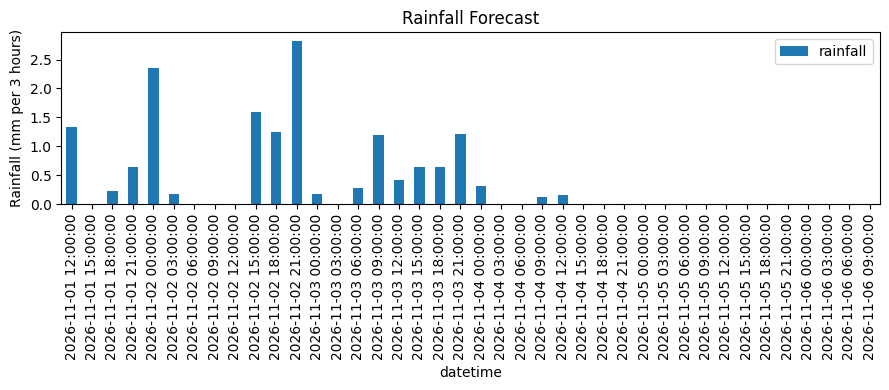

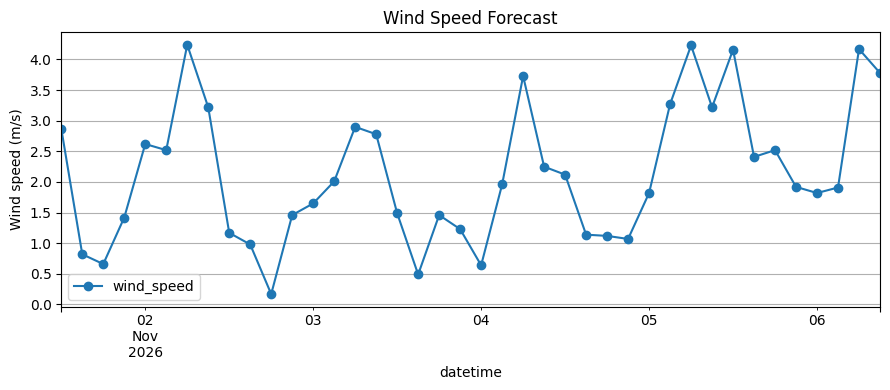

In [6]:
df.plot(x="datetime", y="temperature", kind="line", marker="o",
        title="Pune Temperature Forecast", figsize=(9, 4), grid=True)
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

df.plot(x="datetime", y="rainfall", kind="bar",
        title="Rainfall Forecast", figsize=(9, 4))
plt.ylabel("Rainfall (mm per 3 hours)")
plt.tight_layout()
plt.show()

df.plot(x="datetime", y="wind_speed", kind="line", marker="o",
        title="Wind Speed Forecast", figsize=(9, 4), grid=True)
plt.ylabel("Wind speed (m/s)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Daily aggregation

,date,avg_temperature,max_temperature,avg_humidity,total_rainfall
0,2026-11-01,26.48,27.04,63.50,2.20
1,2026-11-02,26.83,30.92,72.75,8.21
2,2026-11-03,26.25,30.27,68.12,4.58
3,2026-11-04,26.56,30.30,61.75,0.60
4,2026-11-05,26.90,31.43,56.88,0.00
5,2026-11-06,27.41,31.77,54.50,0.00


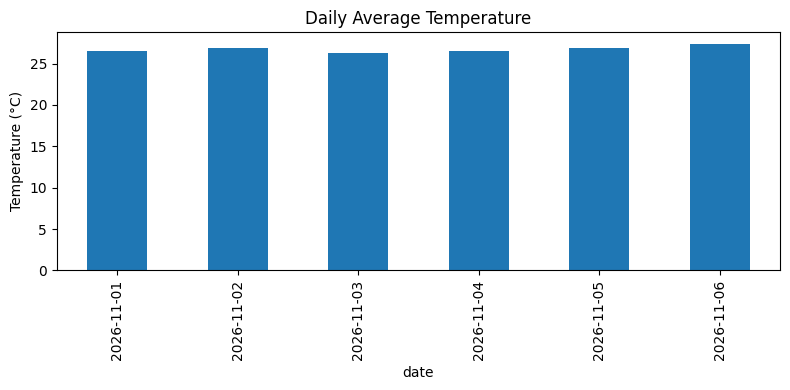

In [7]:
df["date"] = df["datetime"].dt.date
daily = df.groupby("date").agg(
    avg_temperature=("temperature", "mean"),
    max_temperature=("temperature", "max"),
    avg_humidity=("humidity", "mean"),
    total_rainfall=("rainfall", "sum")
).reset_index()

display(daily.round(2))
daily.plot(x="date", y="avg_temperature", kind="bar",
           title="Daily Average Temperature", legend=False, figsize=(8, 4))
plt.ylabel("Temperature (°C)")
plt.tight_layout()
plt.show()

## 8. Location / geographical information

In [8]:
# Coordinates are supplied by the API response.
print("City:", weather["city"]["name"])
print("Latitude:", weather["city"]["coord"]["lat"])
print("Longitude:", weather["city"]["coord"]["lon"])

# Optional map (install folium with: pip install folium)
import folium
m = folium.Map(
    location=[weather["city"]["coord"]["lat"], weather["city"]["coord"]["lon"]],
    zoom_start=10
)
folium.Marker(
    [weather["city"]["coord"]["lat"], weather["city"]["coord"]["lon"]],
    popup="Pune Weather"
).add_to(m)
m

City: Pune
Latitude: 18.5196
Longitude: 73.8553


## 9. Correlation between weather attributes

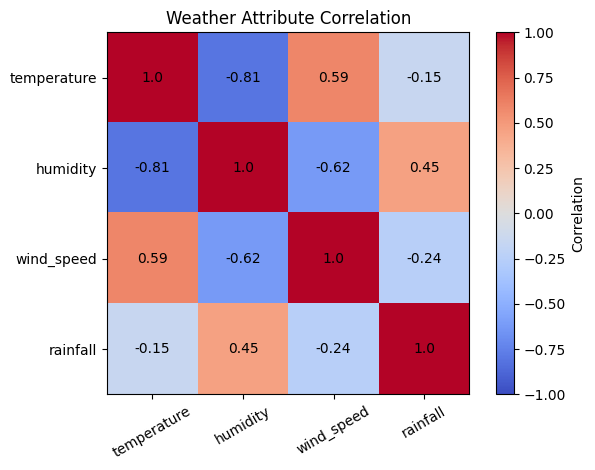

In [9]:
corr = df[["temperature", "humidity", "wind_speed", "rainfall"]].corr()
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(4), corr.columns, rotation=30)
plt.yticks(range(4), corr.columns)
plt.title("Weather Attribute Correlation")
for i in range(4):
    for j in range(4):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha="center", va="center")
plt.tight_layout()
plt.show()

## 10. Export cleaned data

In [10]:
df.to_csv("Pune_Weather_Cleaned.csv", index=False)
daily.to_csv("Pune_Daily_Weather_Summary.csv", index=False)
print("Cleaned and daily summary files saved.")

Cleaned and daily summary files saved.


## Conclusion
Weather forecast data for Pune was retrieved from an OpenWeatherMap response. Temperature, humidity, wind speed and rainfall were extracted, cleaned, summarized and visualized. Daily aggregation, location coordinates and correlation analysis were also performed.

**Limitation:** The supplied data covers only about five days for one location. It cannot be used to make long-term seasonal conclusions or compare multiple cities.